# Memory retention

How fast do people forget? The retention model of Lee & Wagenmakers
(2013, chapter 10.1) describes the share of recalled items as an
exponential decay over time. This case study takes the PyMC version of
the model and uses it in `elicito` with the PyMC adapter.

The case study has three parts:

1. **Translate.** One call turns the PyMC model into a TensorFlow model.
2. **Validate.** The two models give the same samples. The TensorFlow model
   is fast enough for an elicitation.
3. **Elicit.** Three experts give their knowledge about the recall of a
   new participant. `elicito` learns a prior from each expert. PyMC then
   fits the model with each prior.

**Main results**

- The two models give the same distributions: the largest KS distance is
  0.022.
- The translated model draws 10 000 samples about 20 times faster than
  PyMC.
- The learned priors reproduce the quantiles of the simulated expert 3,
  but not all quantiles of experts 1 and 2, who give quantiles directly.
- The data dominate all three elicited priors: the posterior means of
  $\alpha$ are 0.30 to 0.35 for all four priors.
- The posterior predictive check shows that one curve for all
  participants does not fit participants 1 and 3.

> **Note:** the adapter needs Python 3.12 or later and the optional
> dependency `pymc`. Install it with `pip install "elicito[pymc]"`.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
# mkdocs runs the notebook in the repository root; the data are next to it
if os.path.isdir("docs/case-studies"):
    os.chdir("docs/case-studies")

In [2]:
import time
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
import tensorflow as tf
import tensorflow_probability as tfp
from scipy import stats

import elicito as el
from elicito.adapter import pymc as adapter_pymc

SEED = tf.constant([2013, 10], dtype=tf.int32)
DRAWS = 10_000
TOL = 0.05  # largest KS distance D that shows agreement

In [3]:
import logging

# hide the INFO messages of pm.sample; the progress bar stays
logging.getLogger("pymc").setLevel(logging.WARNING)

# colours of the figures: one fixed colour for each entity
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e1",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.titlesize": "medium",
        "legend.frameon": False,
    }
)

## The recall task

Participants study a list of 18 items. After a delay, they recall as many
items as they can. The data count the recalled items of three
participants at nine delays. A fourth participant has no data: the model
predicts the recall of this participant.

In [4]:
t = np.array([1, 2, 4, 7, 12, 21, 35, 59, 99, 200])  # the ten delays
n = 18  # items
k = np.array(
    [
        [18, 18, 16, 13, 9, 6, 4, 4, 4],
        [17, 13, 9, 6, 4, 4, 4, 4, 4],
        [14, 10, 6, 4, 4, 4, 4, 4, 4],
    ]
)
ns = 4  # participants, with participant 4 not observed
ns_obs, nt_obs = k.shape  # the observed participants and delays
t_obs = t[:nt_obs]

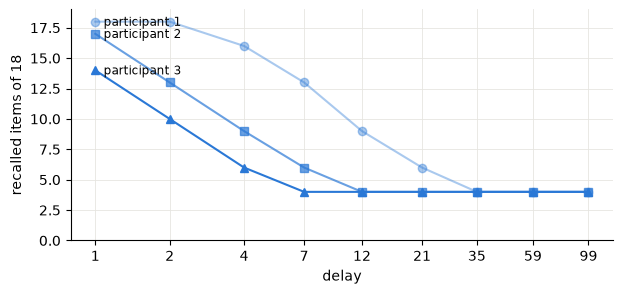

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
for i, (counts, marker) in enumerate(zip(k, ("o", "s", "^"))):
    ax.plot(t_obs, counts, marker=marker, color=BLUE, alpha=0.4 + 0.3 * i)
    ax.annotate(
        f"participant {i + 1}",
        (t_obs[0], counts[0]),
        xytext=(6, -3),
        textcoords="offset points",
        fontsize="small",
    )
ax.set(
    xscale="log",
    xlabel="delay",
    ylabel=f"recalled items of {n}",
    ylim=(0, n + 1),
    xticks=t_obs,
    xticklabels=t_obs,
)
ax.minorticks_off()
plt.show()

Recall drops fast in the first delays. From delay 35 on, all three
participants recall 4 items: this is the floor of the curve.

## The model

All participants share a decay rate $\alpha$ and a baseline $\beta$. At
delay $t$, a participant recalls an item with the probability

$$\theta_t = \min\left(1, \exp(-\alpha t) + \beta\right),$$

and the number of recalled items is
$k_t \sim \operatorname{Binomial}(\theta_t, 18)$. The book gives both
parameters a $\operatorname{Beta}(1, 1)$ prior.

The model has two outputs. `kij` holds the observed counts. `kij_ppc`
holds the predicted counts of all four participants at all ten delays.
The PyMC model follows the rules of [Use a PyMC model][use-a-pymc-model]:
each input of a prior is a named `pm.Data` node.

In [6]:
BOOK_PRIOR = {"alpha_a": 1.0, "alpha_b": 1.0, "beta_a": 1.0, "beta_b": 1.0}


def beta_prior(name: str) -> Any:
    """Add a Beta(1, 1) prior with pm.Data inputs to the model"""
    return pm.Beta(
        name, alpha=pm.Data(f"{name}_a", 1.0), beta=pm.Data(f"{name}_b", 1.0)
    )


with pm.Model() as model:
    alpha = beta_prior("alpha")
    beta = beta_prior("beta")

    # the observed counts
    theta = pm.math.exp(-alpha * t_obs) + beta
    thetaj = pm.Deterministic(
        "thetaj", pm.math.clip(pm.math.stack([theta] * ns_obs), 0, 1)
    )
    pm.Binomial("kij", p=thetaj, n=n, observed=k)

    # the predicted counts of all participants at all delays
    theta_all = pm.math.minimum(pm.math.exp(-alpha * t) + beta, 1.0)
    pm.Deterministic(
        "kij_ppc", pm.Binomial.dist(n=n, p=pm.math.stack([theta_all] * ns))
    )

## From PyMC to TensorFlow

`adapter_pymc.parameters` lists the priors that `elicito` reads.
`adapter_pymc.model` returns the translated model. It returns each
observed variable and each `pm.Deterministic` by name: here `kij`,
`thetaj` and `kij_ppc`.

In [7]:
print([(p["name"], p["family"].__name__) for p in adapter_pymc.parameters(model)])

generative_model = adapter_pymc.model(model)()

[('alpha', 'Beta'), ('beta', 'Beta')]


## Do the two models agree?

Both models get the same priors. The TensorFlow model and `pm.draw` each
draw 10 000 samples. If the translation is correct, the two samples come
from the same distribution.

The Kolmogorov-Smirnov (KS) distance $D$ measures the largest difference
between the two cumulative distributions. With 10 000 draws, a value
below 0.05 shows agreement. For each output, the table shows the largest
$D$ of all its elements.

In [8]:
def sample_priors(pymc_model: Any, draws: int, seed: Any) -> Any:
    """Sample the priors of a PyMC model in TensorFlow, shape (1, draws, P)"""
    parameters = adapter_pymc.parameters(pymc_model)
    seeds = tfp.random.split_seed(seed, n=len(parameters))
    columns = []
    for parameter, param_seed in zip(parameters, seeds):
        args = {
            arg: float(pymc_model[hyper["name"]].get_value())
            for arg, hyper in parameter["hyperparams"].items()
        }
        columns.append(parameter["family"](**args).sample(draws, seed=param_seed))
    return tf.stack(columns, axis=-1)[None]


OUTPUTS = ("thetaj", "kij", "kij_ppc")
seed_priors, seed_model = tfp.random.split_seed(SEED)
prior_samples = sample_priors(model, DRAWS, seed_priors)
tf_out = generative_model(prior_samples, seed=seed_model)
pm_out = pm.draw([model[name] for name in OUTPUTS], draws=DRAWS, random_seed=1)

# float32 and float64 differ in the last digits: round both, in float64
samples = {
    name: {
        "TensorFlow": np.asarray(tf_out[name][0], dtype=float)
        .reshape(DRAWS, -1)
        .round(6),
        "PyMC": np.asarray(pm_values, dtype=float).reshape(DRAWS, -1).round(6),
    }
    for name, pm_values in zip(OUTPUTS, pm_out)
}
distance = {
    name: max(
        stats.ks_2samp(
            pair["TensorFlow"][:, j], pair["PyMC"][:, j], method="asymp"
        ).statistic
        for j in range(pair["PyMC"].shape[1])
    )
    for name, pair in samples.items()
}

print(f"{'output':<10}{'TensorFlow mean, sd':>22}{'PyMC mean, sd':>18}{'D':>8}")
for name, pair in samples.items():
    tf_stats, pm_stats = (
        f"{values.mean():.2f}, {values.std():.2f}" for values in pair.values()
    )
    print(f"{name:<10}{tf_stats:>22}{pm_stats:>18}{distance[name]:>8.3f}")
assert max(distance.values()) < TOL

output       TensorFlow mean, sd     PyMC mean, sd       D
thetaj                0.62, 0.31        0.63, 0.31   0.021
kij                  11.21, 5.79       11.31, 5.76   0.022
kij_ppc              11.00, 5.80       11.09, 5.77   0.019


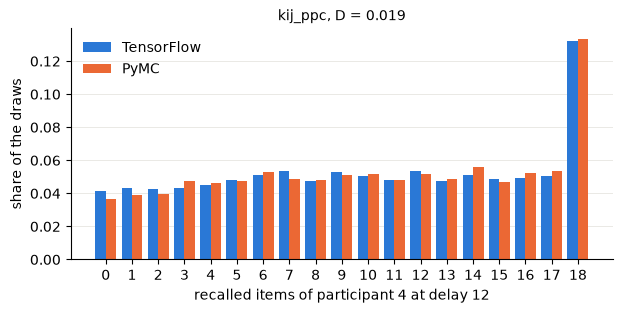

In [9]:
DELAY = 4  # index of delay 12
J = 3 * len(t) + DELAY  # participant 4, delay 12, in the flat kij_ppc

fig, ax = plt.subplots(figsize=(7, 3))
values_k = np.arange(n + 1)
for offset, ((label, values), color) in zip(
    (-0.2, 0.2), zip(samples["kij_ppc"].items(), (BLUE, ORANGE))
):
    share = np.bincount(values[:, J].astype(int), minlength=n + 1) / DRAWS
    ax.bar(values_k + offset, share, width=0.4, color=color, label=label)
ax.set(
    xlabel=f"recalled items of participant 4 at delay {t[DELAY]}",
    ylabel="share of the draws",
    xticks=values_k,
    title=f"kij_ppc, D = {distance['kij_ppc']:.3f}",
)
ax.grid(axis="x", visible=False)
ax.legend()
plt.show()

The distributions of the two models overlap. Under the book prior, 13 %
of the draws recall all 18 items at delay 12: there, the rate
$\exp(-\alpha t) + \beta$ is 1.

## How fast is the translated model?

During the elicitation, `elicito` runs the model at each step of the
search. A fast model is therefore important. We time one forward pass of
10 000 samples. Each model runs once before the timing, so the time does
not include the compilation.

PyMC draws one sample per call of its compiled function. The TensorFlow
model draws all samples in one call.

In [10]:
REPEATS = 5

draw_pymc = pm.compile([], [model[name] for name in OUTPUTS], random_seed=1)


def run_pymc() -> None:
    """Draw DRAWS samples with the compiled PyMC function"""
    for _ in range(DRAWS):
        draw_pymc()


def run_tensorflow() -> None:
    """Draw DRAWS samples with the translated model"""
    out = generative_model(prior_samples, seed=seed_model)
    _ = [value.numpy() for value in out.values()]


seconds = {}
for label, run in (("TensorFlow", run_tensorflow), ("PyMC", run_pymc)):
    run()  # warm-up
    times = []
    for _ in range(REPEATS):
        start = time.perf_counter()
        run()
        times.append(time.perf_counter() - start)
    seconds[label] = float(np.median(times))

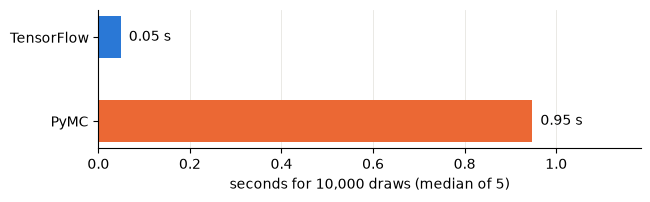

In [11]:
fig, ax = plt.subplots(figsize=(7, 1.8))
labels = list(seconds)
ax.barh(labels, list(seconds.values()), color=[BLUE, ORANGE], height=0.5)
for i, value in enumerate(seconds.values()):
    ax.text(value, i, f"  {value:.2f} s", va="center")
ax.set(
    xlabel=f"seconds for {DRAWS:,} draws (median of {REPEATS})",
    xlim=(0, 1.25 * max(seconds.values())),
)
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
plt.show()

The translated model is about 20 times faster. The exact times depend on
the computer and its load.

## Three experts

Participant 4 has no data, so the experts judge this participant. Each
expert gives the median and a plausible interval, the 5 % and the 95 %
quantile, of the recalled items at the delays 4, 12 and 59:

- **`k4_t4`, `k4_t12`, `k4_t59`:** "A new person studies 18 items. How many does the
  person recall after a delay of 4 (12, 59)?"

For the 5 % quantile, the question is: "Give a value that is too low
with a probability of 5 %."

| Expert | delay 4 | delay 12 | delay 59 |
| :-- | :-- | :-- | :-- |
| 1 | 15, 16, 18 | 10, 14, 17 | 2, 9, 16 |
| 2 | 12, 16, 18 | 7, 14, 18 | 0, 9, 18 |
| 3 | simulated | simulated | simulated |

Experts 1 and 2 give the quantiles directly, as a real expert does.
Expert 2 gives wider intervals than expert 1 at all three delays. Expert
3 is a simulated expert: the quantiles come from the priors
$\alpha \sim \operatorname{Beta}(2, 18)$ and
$\beta \sim \operatorname{Beta}(4, 16)$.

`kappa` weights a spread penalty: the negative mean log standard
deviation of the priors. It keeps a prior from collapsing to a point
mass. Five replications with different seeds show if the result depends
on the seed.

In [12]:
DELAYS = (2, 4, 7)  # indices of t: the delays 4, 12 and 59
PROBS = (0.05, 0.50, 0.95)


def recall_at(j: int) -> Any:
    """Return a target function that selects delay j of participant 4"""

    def target(kij_ppc: Any) -> Any:
        return kij_ppc[:, :, 3, j]

    return target


targets = [
    el.quantiles(f"k4_t{t[j]}", output=recall_at(j), probs=PROBS) for j in DELAYS
]


def simulated_expert(alpha: tuple[float, float], beta: tuple[float, float]) -> Any:
    """Return the quantiles of participant 4 under known Beta priors"""
    values = dict(zip(BOOK_PRIOR, (*alpha, *beta)))
    pm.set_data(values, model=model)
    counts = pm.draw(model["kij_ppc"][3, list(DELAYS)], draws=10_000, random_seed=2013)
    pm.set_data(BOOK_PRIOR, model=model)
    quantiles = np.quantile(counts, PROBS, axis=0).T
    return {f"k4_t{t[j]}": list(q) for j, q in zip(DELAYS, quantiles)}


EXPERTS = {
    "Expert 1": {"k4_t4": [15, 16, 18], "k4_t12": [10, 14, 17], "k4_t59": [2, 9, 16]},
    "Expert 2": {"k4_t4": [12, 16, 18], "k4_t12": [7, 14, 18], "k4_t59": [0, 9, 18]},
    "Expert 3": simulated_expert(alpha=(2, 18), beta=(4, 16)),
}

In [13]:
fits = {}
for expert, quantiles in EXPERTS.items():
    eliobj = el.Elicit(
        model, targets, seeds=(1, 2, 3, 4, 5), epochs=400, kappa=0.1, verbose=False
    )
    fits[expert] = eliobj.fit(quantiles)

## Did the elicitation succeed?

The loss must go down and level off. The elicited quantiles must be near
the quantiles of the expert: this is the check of the elicitation.

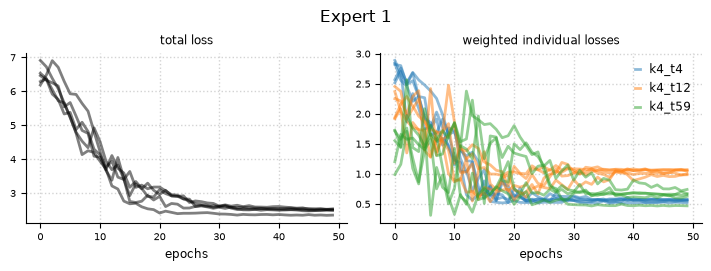

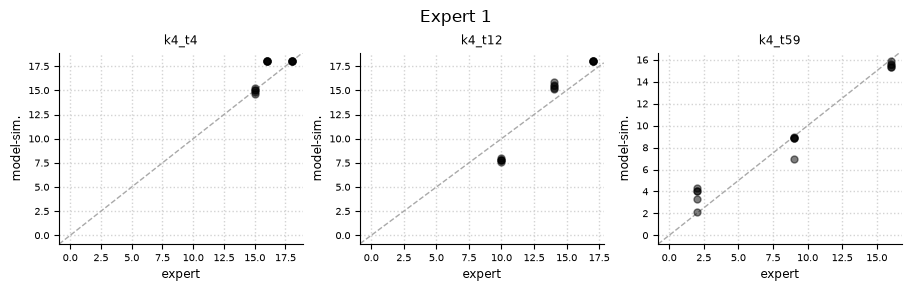

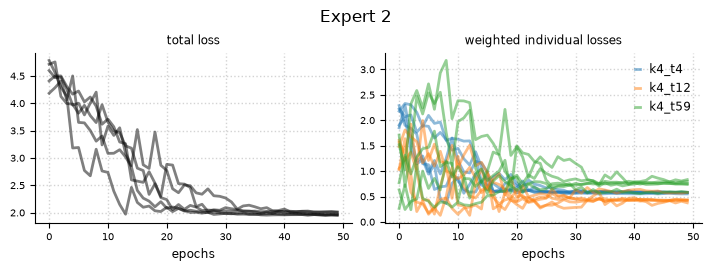

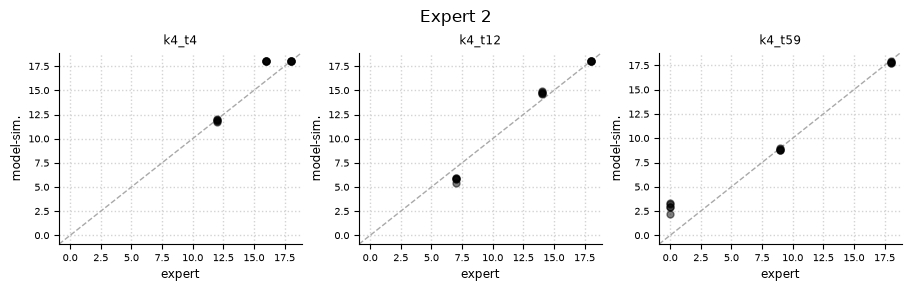

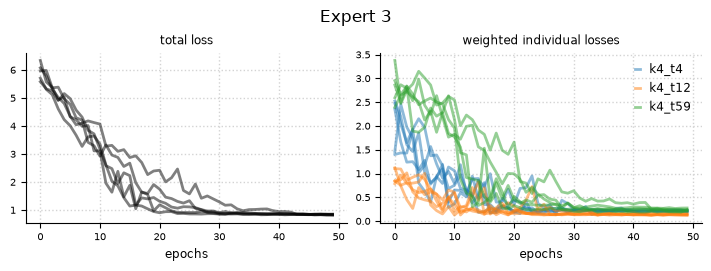

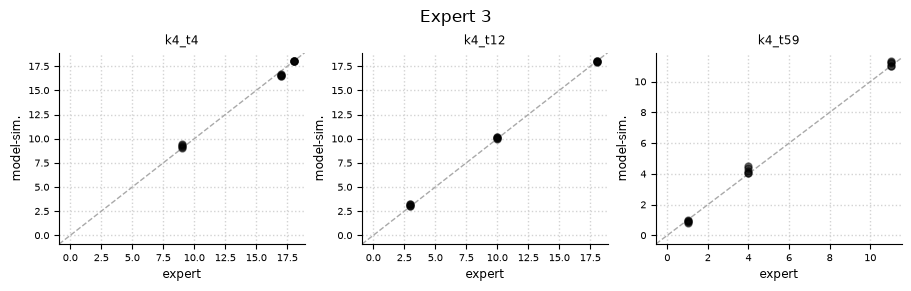

In [14]:
for expert, fit in fits.items():
    fig, _ = fit.plot.loss(figsize=(7, 2.6))
    fig.suptitle(expert)
    plt.show()
    fig, _ = fit.plot.elicits(cols=3, figsize=(9, 2.8))
    fig.suptitle(expert)
    plt.show()

- **Expert 3.** All nine elicited quantiles are on the diagonal. The
  quantiles come from priors of the model, so the model can give them.
- **Experts 1 and 2.** Some elicited quantiles are off the diagonal. At
  delay 4, both experts give a median of 16, and the model gives 18. For
  expert 1 at delay 12, the 5 % quantile is about 8 instead of 10. The
  learned priors give the best compromise that the search finds.

## From prior to posterior

We now give each elicited prior back to the PyMC model with
`pm.set_data`. PyMC then fits the model to the data. The book prior,
$\operatorname{Beta}(1, 1)$, is the reference. We use the replication with
the lowest loss.

Where $\exp(-\alpha t) + \beta$ exceeds 1, the rate is 1, and an observed
count below 18 has zero probability. A random start of the sampler can
therefore fail. `INITVALS` starts every chain in the region of the
posterior. The model gives divergences at the default `target_accept`,
with any prior, so all runs use 0.95.

In [15]:
PRIORS = {"Book": BOOK_PRIOR}
PRIORS |= {expert: fit.hyperparameters() for expert, fit in fits.items()}

for label, prior in PRIORS.items():
    print(f"{label:<10}" + "  ".join(f"{k} {v:.2f}" for k, v in prior.items()))

Book      alpha_a 1.00  alpha_b 1.00  beta_a 1.00  beta_b 1.00
Expert 1  alpha_b 24.86  beta_b 6.76  alpha_a 2.36  beta_a 5.37
Expert 2  alpha_b 9.91  beta_b 5.45  alpha_a 1.19  beta_a 3.99
Expert 3  alpha_b 13.12  beta_b 21.23  alpha_a 1.62  beta_a 5.59


In [16]:
PARAMETERS = ("alpha", "beta")
INITVALS = {"alpha": 0.3, "beta": 0.2}

posteriors, predictives = {}, {}
for label, prior in PRIORS.items():
    with model:
        pm.set_data(prior)
        idata = pm.sample(
            1000,
            tune=1000,
            chains=4,
            target_accept=0.95,
            initvals=INITVALS,
            random_seed=1,
            progressbar=True,
        )
        pm.sample_posterior_predictive(
            idata, extend_inferencedata=True, random_seed=1, progressbar=False
        )
    posteriors[label] = idata
    predictives[label] = idata.posterior_predictive

print(
    f"{'prior':<10}{'parameter':<10}{'mean':>6}{'90 % interval':>16}{'divergences':>13}"
)
for label, idata in posteriors.items():
    divergences = int(idata.sample_stats["diverging"].sum())
    for name in PARAMETERS:
        values = idata.posterior[name].values.ravel()
        low, high = np.quantile(values, [0.05, 0.95])
        print(
            f"{label:<10}{name:<10}{values.mean():>6.2f}"
            f"{f'{low:.2f}, {high:.2f}':>16}{divergences:>13}"
        )

Output()

There were 8 divergences after tuning. Increase `target_accept` or reparameterize.


Output()

There were 5 divergences after tuning. Increase `target_accept` or reparameterize.


Output()

There were 5 divergences after tuning. Increase `target_accept` or reparameterize.


Output()

There were 10 divergences after tuning. Increase `target_accept` or reparameterize.


prior     parameter   mean   90 % interval  divergences
Book      alpha       0.35      0.27, 0.45            8
Book      beta        0.24      0.19, 0.29            8
Expert 1  alpha       0.30      0.24, 0.36            5
Expert 1  beta        0.21      0.17, 0.25            5
Expert 2  alpha       0.33      0.25, 0.41            5
Expert 2  beta        0.23      0.18, 0.28            5
Expert 3  alpha       0.30      0.24, 0.38           10
Expert 3  beta        0.22      0.17, 0.26           10


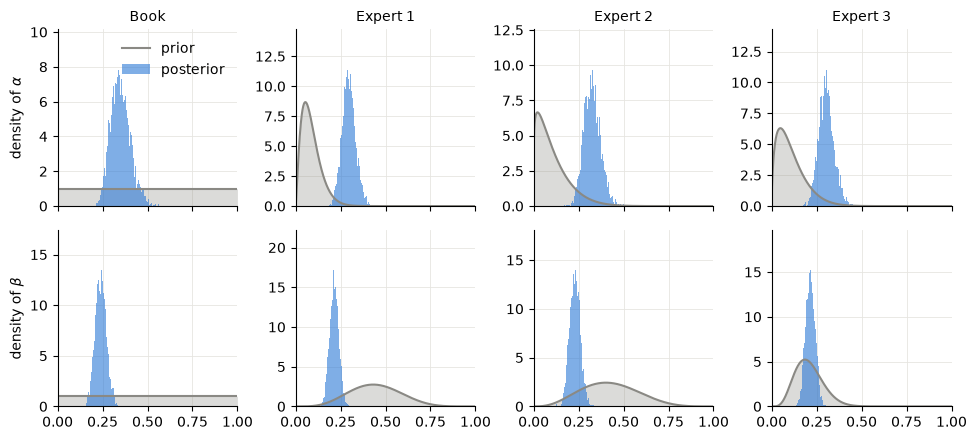

In [17]:
SYMBOL = {"alpha": r"$\alpha$", "beta": r"$\beta$"}
x_grid = np.linspace(0, 1, 1000)

fig, axs = plt.subplots(len(PARAMETERS), len(PRIORS), figsize=(10, 4.5), sharex=True)
for row, name in enumerate(PARAMETERS):
    for col, (label, prior) in enumerate(PRIORS.items()):
        ax = axs[row, col]
        density = stats.beta(prior[f"{name}_a"], prior[f"{name}_b"]).pdf(x_grid)
        ax.fill_between(x_grid, density, color=GREY, alpha=0.3, lw=0)
        ax.plot(x_grid, density, color=GREY, lw=1.5, label="prior")
        heights, *_ = ax.hist(
            posteriors[label].posterior[name].values.ravel(),
            bins=np.linspace(0, 1, 200),
            density=True,
            histtype="stepfilled",
            color=BLUE,
            alpha=0.6,
            label="posterior",
        )
        # a Beta density with a parameter below 1 is infinite at a bound
        ax.set(xlim=(0, 1), ylim=(0, 1.3 * heights.max()))
        if row == 0:
            ax.set_title(label)
        if col == 0:
            ax.set_ylabel(f"density of {SYMBOL[name]}")
axs[0, 0].legend()
fig.tight_layout()
plt.show()

The posteriors of the four priors are almost the same. The mean of
$\alpha$ is 0.35 (book), 0.30 (expert 1), 0.33 (expert 2) and 0.30
(expert 3). The mean of $\beta$ is 0.21 to 0.24. The elicited priors of
$\alpha$ put most mass below 0.2, but the 27 observed counts move the
posterior to about 0.3. With `target_accept=0.95`, PyMC still reports 5
to 10 divergences for each prior.

## Does the model fit the data?

A posterior predictive check simulates new data from the fitted model,
once for each posterior draw. The figure repeats the first figure, with
one panel for each prior.

The dots are the observed counts of the three participants. The model
has no differences between the participants, so one band shows the 90 %
interval of a new participant, at all ten delays.

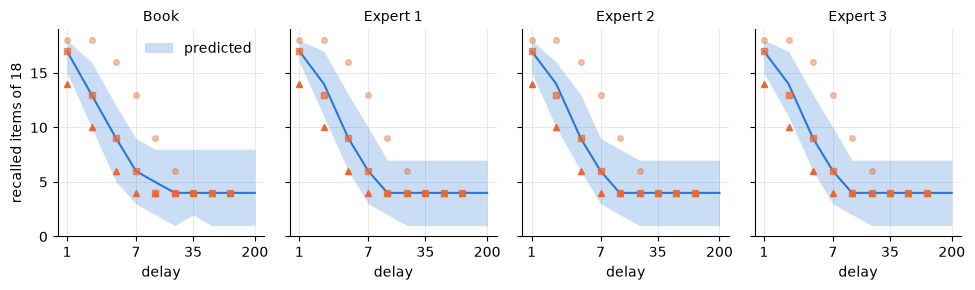

In [18]:
fig, axs = plt.subplots(1, len(PRIORS), figsize=(10, 3), sharey=True)
for ax, (label, idata) in zip(axs, posteriors.items()):
    new = idata.posterior["kij_ppc"].values.reshape(-1, ns, len(t))[:, 3]
    low, mid, high = np.quantile(new, [0.05, 0.5, 0.95], axis=0)
    ax.fill_between(t, low, high, color=BLUE, alpha=0.25, lw=0, label="predicted")
    ax.plot(t, mid, color=BLUE, lw=1.5)
    for i, marker in enumerate(("o", "s", "^")):
        ax.plot(t_obs, k[i], marker, color=ORANGE, ms=4, alpha=0.4 + 0.3 * i)
    ax.set(
        title=label,
        xscale="log",
        xlabel="delay",
        ylim=(0, n + 1),
        xticks=t[::3],
        xticklabels=t[::3],
    )
    ax.minorticks_off()
axs[0].set_ylabel(f"recalled items of {n}")
axs[0].legend(loc="upper right")
fig.tight_layout()
plt.show()

The four panels are almost the same: the data dominate the priors. The
observed counts of participant 2 (squares) follow the median. Participant
1 (circles) recalls more items than the band at the delays 2 to 12.
Participant 3 (triangles) recalls fewer at the delays 1 to 4. The model
has one decay rate for all participants. The differences between the
participants need a model with individual differences, as model 10.2 of
the book.

## Takeaways

- **Translation.** One call translates the PyMC model. The largest KS
  distance of the three outputs is 0.022.
- **Speed.** The translated model is about 20 times faster than PyMC.
- **Direct quantiles.** The learned prior may not reproduce all
  quantiles that an expert gives directly. The elicitation check shows
  which quantiles it misses.
- **Posterior predictive check.** The check shows a misfit that no prior
  can repair: the model has no differences between the participants.

## Appendix

The PyMC3 model comes from the notebook
[MemoryRetention.ipynb](https://github.com/pymc-devs/pymc-resources/blob/main/BCM/CaseStudies/MemoryRetention.ipynb)
of pymc-resources (MIT licence). See the [case studies](index.md) for the
credit.

In [19]:
import importlib.metadata
import sys

print(f"Python {sys.version.split()[0]}")
for package in ("elicito", "pymc", "tensorflow", "tensorflow-probability"):
    print(f"{package} {importlib.metadata.version(package)}")

Python 3.13.13
elicito 0.7.1a1
pymc 6.3.2
tensorflow 2.20.0
tensorflow-probability 0.25.0


## References

- Lee, M. D., & Wagenmakers, E.-J. (2013). *Bayesian Cognitive Modeling: A
  Practical Course*. Cambridge University Press.